In [1]:
%pip install -q imbalanced-learn
import os
import zipfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score)
from imblearn.over_sampling import SMOTE
print("Libraries imported successfully.")


Libraries imported successfully.


In [5]:
zip_path = "/content/creditcard.csv.zip"
data_folder = "/content/clean_dataset"
csv_path = os.path.join(data_folder, "creditcard.csv")
if not os.path.exists(csv_path):
    if not os.path.exists(zip_path):
        raise FileNotFoundError(
            "Upload creditcard.csv.zip to Google Colab first.")
    os.makedirs(data_folder, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(data_folder)
df = pd.read_csv(csv_path)
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nClass distribution:")
print(df["Class"].value_counts().sort_index())
print("\nClass percentages:")
print(
    (df["Class"].value_counts(normalize=True).sort_index() * 100)
    .round(4))
display(df.head())

Dataset shape: (284807, 31)
Missing values: 0
Duplicate rows: 1081

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Class percentages:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
X = df.drop(columns=["Class"])
y = df["Class"]
print("Features:", X.shape)
print("Target:", y.shape)

Features: (284807, 30)
Target: (284807,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X,y,
    test_size=0.20,
    random_state=42,
    stratify=y)
X_train = X_train.copy()
X_test = X_test.copy()
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("\nTraining class distribution:")
print(y_train.value_counts())
print("\nTesting class distribution:")
print(y_test.value_counts())

Training data: (227845, 30)
Testing data: (56962, 30)

Training class distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing class distribution:
Class
0    56864
1       98
Name: count, dtype: int64


In [8]:
scaler = StandardScaler()
columns_to_scale = ["Time", "Amount"]
X_train.loc[:, columns_to_scale] = scaler.fit_transform(
    X_train[columns_to_scale])
X_test.loc[:, columns_to_scale] = scaler.transform(
    X_test[columns_to_scale])
print("Feature scaling completed.")

Feature scaling completed.


In [9]:
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train,
    y_train)
print("Before SMOTE:")
print(y_train.value_counts())
print("\nAfter SMOTE:")
print(y_train_balanced.value_counts())
print("\nTest distribution — unchanged:")
print(y_test.value_counts())

Before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

After SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64

Test distribution — unchanged:
Class
0    56864
1       98
Name: count, dtype: int64


In [10]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42)
lr_model.fit(X_train_balanced, y_train_balanced)
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1)
rf_model.fit(X_train_balanced, y_train_balanced)
print("Both models trained successfully.")

Both models trained successfully.


In [11]:
lr_predictions = lr_model.predict(X_test)
rf_predictions = rf_model.predict(X_test)
print("=== LOGISTIC REGRESSION ===")
print(
    classification_report(
        y_test,
        lr_predictions,
        target_names=["Legitimate", "Fraud"],
        zero_division=0))
print("=== RANDOM FOREST ===")
print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=["Legitimate", "Fraud"],
        zero_division=0))

=== LOGISTIC REGRESSION ===
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962

=== RANDOM FOREST ===
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.85      0.84      0.84        98

    accuracy                           1.00     56962
   macro avg       0.92      0.92      0.92     56962
weighted avg       1.00      1.00      1.00     56962



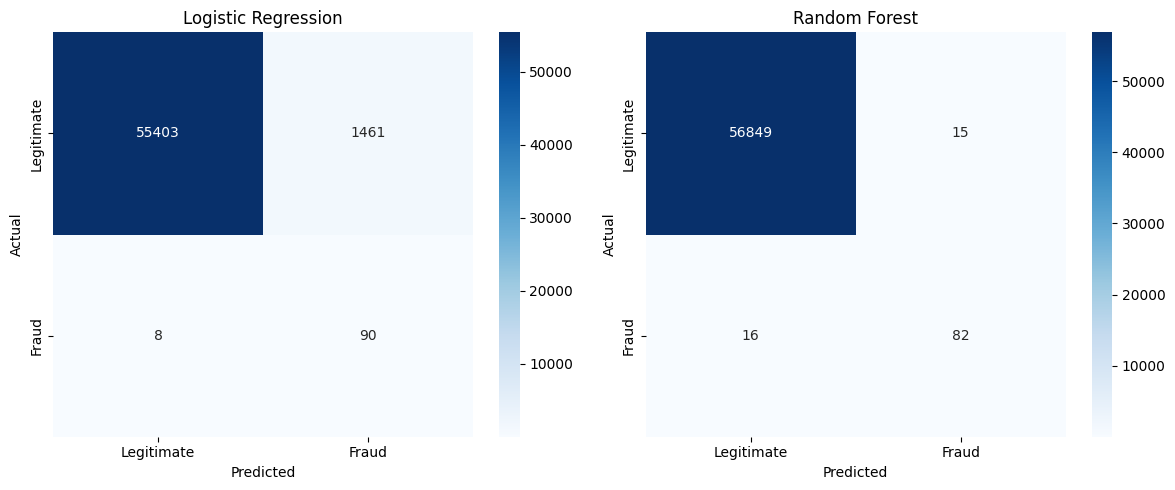

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, predictions in [
    (axes[0], "Logistic Regression", lr_predictions),
    (axes[1], "Random Forest", rf_predictions)
]:
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()


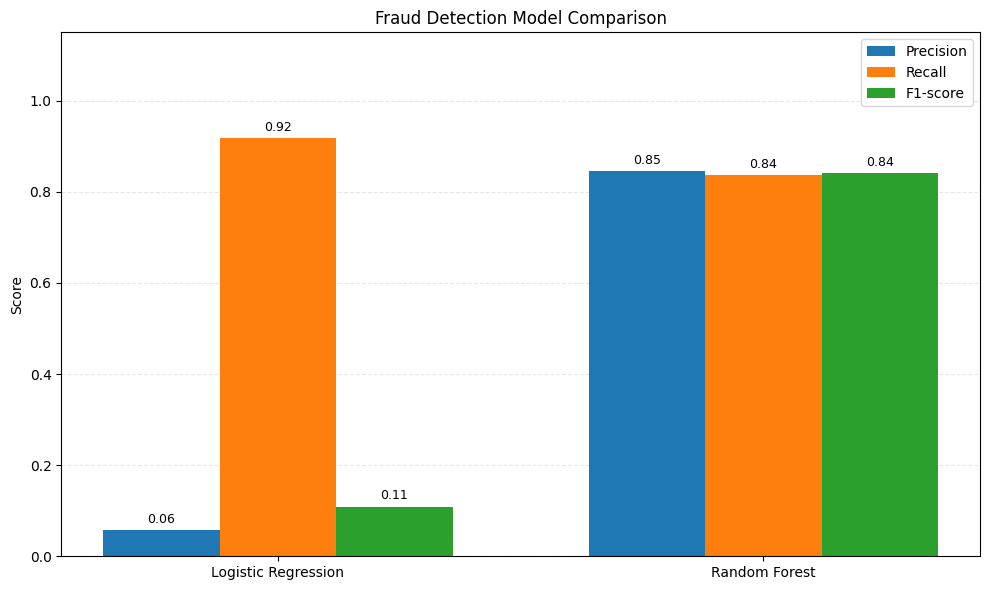

Model comparison chart saved.


In [14]:
models = ["Logistic Regression", "Random Forest"]
scores = {
    "Precision": [
        precision_score(y_test, lr_predictions, zero_division=0),
        precision_score(y_test, rf_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, lr_predictions, zero_division=0),
        recall_score(y_test, rf_predictions, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, lr_predictions, zero_division=0),
        f1_score(y_test, rf_predictions, zero_division=0)]}
x = np.arange(len(models))
width = 0.24
fig, ax = plt.subplots(figsize=(10, 6))
for i, (metric, values) in enumerate(scores.items()):
    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=metric)
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Score")
ax.set_title("Fraud Detection Model Comparison")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
print("Model comparison chart saved.")

In [15]:
chosen_predictions = pd.Series(
    rf_predictions,
    index=X_test.index)
tn, fp, fn, tp = confusion_matrix(
    y_test,
    chosen_predictions,
    labels=[0, 1]).ravel()
print("=== RANDOM FOREST BUSINESS IMPACT ===")
print("Legitimate transactions correctly identified:", tn)
print("Legitimate transactions incorrectly flagged:", fp)
print("Fraud transactions missed:", fn)
print("Fraud transactions detected:", tp)
fraud_detection_rate = recall_score(
    y_test, chosen_predictions, zero_division=0) * 100
original_amounts = df.loc[X_test.index, "Amount"]
actual_fraud = y_test == 1
caught_fraud = actual_fraud & (chosen_predictions == 1)
missed_fraud = actual_fraud & (chosen_predictions == 0)
print("\nFraud detection rate:", round(fraud_detection_rate, 2), "%")
print(
    "Value of detected fraud transactions:",
    round(original_amounts.loc[caught_fraud].sum(), 2))
print(
    "Value of missed fraud transactions:",
    round(original_amounts.loc[missed_fraud].sum(), 2))

=== RANDOM FOREST BUSINESS IMPACT ===
Legitimate transactions correctly identified: 56849
Legitimate transactions incorrectly flagged: 15
Fraud transactions missed: 16
Fraud transactions detected: 82

Fraud detection rate: 83.67 %
Value of detected fraud transactions: 6813.48
Value of missed fraud transactions: 3831.45


In [16]:
joblib.dump(rf_model, "credit_card_fraud_model.pkl")
joblib.dump(scaler, "credit_card_fraud_scaler.pkl")
joblib.dump(list(X.columns), "credit_card_fraud_features.pkl")
print("Model, scaler, and feature list saved successfully.")

Model, scaler, and feature list saved successfully.


In [17]:
loaded_model = joblib.load("credit_card_fraud_model.pkl")
loaded_scaler = joblib.load("credit_card_fraud_scaler.pkl")
loaded_features = joblib.load("credit_card_fraud_features.pkl")
fraud_indices = y_test[y_test == 1].index[:10]
fraud_samples = X_test.loc[fraud_indices, loaded_features]
actual_labels = y_test.loc[fraud_indices]
saved_predictions = loaded_model.predict(fraud_samples)
test_results = pd.DataFrame({
    "Actual": actual_labels.map({0: "Legitimate", 1: "Fraud"}),
    "Predicted": pd.Series(
        saved_predictions,
        index=fraud_indices).map({0: "Legitimate", 1: "Fraud"})})
display(test_results)
correctly_detected = int(
    ((actual_labels == 1) & (saved_predictions == 1)).sum())
print(
    "Fraud cases correctly detected:",
    correctly_detected,
    "out of",
    len(fraud_samples))
print("Saved model test completed.")

,Actual,Predicted
77348,Fraud,Fraud
102442,Fraud,Fraud
119781,Fraud,Fraud
48094,Fraud,Fraud
42958,Fraud,Fraud
52584,Fraud,Fraud
204064,Fraud,Fraud
151519,Fraud,Fraud
203324,Fraud,Fraud
141260,Fraud,Fraud


Fraud cases correctly detected: 10 out of 10
Saved model test completed.


In [18]:
from google.colab import files
files.download("credit_card_fraud_model.pkl")
files.download("credit_card_fraud_scaler.pkl")
files.download("credit_card_fraud_features.pkl")
files.download("model_comparison.png")
files.download("confusion_matrices.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
reloaded_predictions = loaded_model.predict(X_test[loaded_features])
print(
    "Predictions match:",
    np.array_equal(rf_predictions, reloaded_predictions))
assert np.array_equal(rf_predictions, reloaded_predictions), (
    "Saved model predictions do not match the original model.")
print("Saved model verification passed.")


Predictions match: True
Saved model verification passed.
